<a href="https://colab.research.google.com/github/eugeniatate-duke/XAI-notebooks/blob/main/adversarial_attacks_patches_tate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adversarial Attacks - Adversarial Patches Only

This notebook was created for "Emerging Trends in Explainable AI" course's Adversarial Stickers assignment at Duke University.

Author: Eugenia Tate

Click on the button below to open in Google Colab. You will need access to a GPU to run this code.

[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIPI-590-XAI/Duke-AI-XAI/blob/dev/adversarial-ai-example-notebooks/adversarial_attacks_patches.ipynb)


In [1]:
# import the library used for tensors and neural networks
import torch

# check whether this session can use a gpu
gpu_available = torch.cuda.is_available()
print("gpu available:", gpu_available)

# show the gpu name if one is connected
if gpu_available:
    print("gpu name:", torch.cuda.get_device_name(0))
else:
    print("no gpu connected")

gpu available: True
gpu name: Tesla T4


In [2]:
# import tools for files and numbers
import os
import json
import random
import numpy as np

# import tools for displaying images and progress
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg", "pdf")

# import tools for neural networks and image data
import torch
import torch.nn as nn
import torch.utils.data as data
import torchvision
from torchvision import transforms

# choose folders for downloaded data and saved patches
DATASET_PATH = "/content/data"
CHECKPOINT_PATH = "/content/saved_models/tutorial10"

# set starting points for random number generators
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# make gpu operations more repeatable
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# choose the gpu when it is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("using device:", device)
print("pytorch version:", torch.__version__)
print("torchvision version:", torchvision.__version__)
print("setup complete")

using device: cuda:0
pytorch version: 2.11.0+cu130
torchvision version: 0.26.0+cu130
setup complete


We have again a few download statements. This includes both a dataset, and a few pretrained patches we will use later.

In [3]:
# import tools for downloading and opening zip files
import urllib.request
import zipfile

# use the download location from the starter notebook
base_url = "https://raw.githubusercontent.com/phlippe/saved_models/main/tutorial10/"

# pair each file with its destination folder
downloads = [
    (DATASET_PATH, "TinyImageNet.zip"),
    (CHECKPOINT_PATH, "patches.zip")
]

for folder, filename in downloads:
    # create the destination folder if needed
    os.makedirs(folder, exist_ok=True)
    file_path = os.path.join(folder, filename)

    # download the zip file if we do not already have it
    if not os.path.isfile(file_path):
        print("downloading:", filename)
        urllib.request.urlretrieve(base_url + filename, file_path)
    else:
        print("already downloaded:", filename)

    # extract the files into their destination folder
    print("extracting:", filename)
    with zipfile.ZipFile(file_path, "r") as zip_file:
        zip_file.extractall(folder)

    print("finished:", filename)

# check that the expected image folder exists
image_folder = os.path.join(DATASET_PATH, "TinyImageNet")
print("image folder found:", os.path.isdir(image_folder))

downloading: TinyImageNet.zip
extracting: TinyImageNet.zip
finished: TinyImageNet.zip
downloading: patches.zip
extracting: patches.zip
finished: patches.zip
image folder found: True


## Setup

For our experiments in this notebook, we will use common CNN architectures trained on the ImageNet dataset. Such models are luckily provided by PyTorch's torchvision package, and hence we just need to load the model of our preference. For the results on the website and default on Google Colab, we use a ResNet34. Feel free to experiment with other architectures as well, the code is mainly independent of the specific architecture we choose.

In [7]:
# Load CNN architecture pretrained on ImageNet

# choose where to store the downloaded model weights
os.environ["TORCH_HOME"] = CHECKPOINT_PATH

# load resnet34 with weights learned from imagenet
pretrained_model = torchvision.models.resnet34(
    weights="IMAGENET1K_V1"
)

# move the model to our gpu
pretrained_model = pretrained_model.to(device)

# No gradients needed for the network

# use evaluation mode for making predictions; switches model to eval behavior
pretrained_model.eval()

# keep the model weights fixed while we train our patch later
for parameter in pretrained_model.parameters():
    parameter.requires_grad = False # freezes weights

# check that the model loaded on the expected device
print("model loaded: resnet34")
print("model device:", next(pretrained_model.parameters()).device)
print("training mode:", pretrained_model.training)

model loaded: resnet34
model device: cuda:0
training mode: False


To perform adversarial attacks, we also need a dataset to work on. Given that the CNN model has been trained on ImageNet, it is only fair to perform the attacks on data from ImageNet. For this, we provide a small set of pre-processed images from the original ImageNet dataset (note that this dataset is shared under the same [license](http://image-net.org/download-faq) as the original ImageNet dataset). Specifically, we have 5 images for each of the 1000 labels of the dataset. We can load the data below, and create a corresponding data loader.

In [6]:
# Mean and Std from ImageNet (use the normalization values expected by the pretrained model)
NORM_MEAN = np.array([0.485, 0.456, 0.406])
NORM_STD = np.array([0.229, 0.224, 0.225])

# convert images to tensors and normalize their color channels
# No resizing and center crop necessary as images are already preprocessed.
plain_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN,
                         std=NORM_STD)
])

# load images from the extracted dataset folder
imagenet_path = os.path.join(DATASET_PATH, "TinyImageNet")

assert os.path.isdir(imagenet_path), f"Could not find the ImageNet dataset at expected path \"{imagenet_path}\". " + \
                                     f"Please make sure to have downloaded the ImageNet dataset here, or change the {DATASET_PATH=} variable."
dataset = torchvision.datasets.ImageFolder(root=imagenet_path, transform=plain_transforms)

# organize images into batches of 32
data_loader = data.DataLoader(dataset, batch_size=32, shuffle=False, drop_last=False, num_workers=2)

# load readable names for the image categories
with open(os.path.join(imagenet_path, "label_list.json"), "r") as file:
    label_names = json.load(file)

# find the category number for a given name
def get_label_index(label_name):
    return label_names.index(label_name)

# inspect one batch without running the model yet
images, labels = next(iter(data_loader))

print("total images:", len(dataset))
print("total categories:", len(dataset.classes))
print("image batch shape:", images.shape)
print("label batch shape:", labels.shape)
print("first image label:", label_names[labels[0].item()])

total images: 5000
total categories: 1000
image batch shape: torch.Size([32, 3, 224, 224])
label batch shape: torch.Size([32])
first image label: tench


A tensor is an array of numbers. ToTensor() converts each image into that format and scales its pixel values to between 0 and 1.
Normalization then adjusts each red, green, and blue channel using the values expected by the pretrained model.
A batch groups images so the model can process several together. We keep shuffle=False so the initial examples stay in a consistent order.

Before we start with our attacks, we should verify the performance of our model. As ImageNet has 1000 classes, simply looking at the accuracy is not sufficient to tell the performance of a model. Imagine a model that always predicts the true label as the second-highest class in its softmax output. Although we would say it recognizes the object in the image, it achieves an accuracy of 0. In ImageNet with 1000 classes, there is not always one clear label we can assign an image to. This is why for image classifications over so many classes, a common alternative metric is "Top-5 accuracy", which tells us how many times the true label has been within the 5 most-likely predictions of the model. As models usually perform quite well on those, we report the error (1 - accuracy) instead of the accuracy:

In [8]:
# Measuring model's accuracy before adding a patch

# measure how often the model recognizes the correct category
def eval_model(dataset_loader):
    pretrained_model.eval()

    correct_top1 = 0
    correct_top5 = 0
    total_images = 0

    # evaluate predictions without calculating gradients
    with torch.no_grad():
        for images, labels in tqdm(dataset_loader, desc="checking predictions"):
            # move this batch to the gpu
            images = images.to(device)
            labels = labels.to(device)

            # get a score for each of the 1000 categories
            scores = pretrained_model(images)

            # check whether the highest scoring category is correct
            predictions = scores.argmax(dim=1)
            correct_top1 += (predictions == labels).sum().item()

            # check whether the correct category is among the top five
            top5_predictions = scores.topk(5, dim=1).indices
            matches = top5_predictions == labels.unsqueeze(1)
            correct_top5 += matches.any(dim=1).sum().item()

            total_images += labels.size(0)

    top1_accuracy = correct_top1 / total_images
    top5_accuracy = correct_top5 / total_images

    print(f"images checked: {total_images}")
    print(f"top-1 accuracy: {top1_accuracy:.2%}")
    print(f"top-5 accuracy: {top5_accuracy:.2%}")

    return top1_accuracy, top5_accuracy

In [9]:
# save the original model accuracy for later comparison
baseline_top1, baseline_top5 = eval_model(data_loader)

checking predictions:   0%|          | 0/157 [00:00<?, ?it/s]

images checked: 5000
top-1 accuracy: 80.62%
top-5 accuracy: 95.62%


The ResNet34 achives a decent error rate of 4.3% for the top-5 predictions. Next, we can look at some predictions of the model to get more familiar with the dataset. The function below plots an image along with a bar diagram of its predictions. We also prepare it to show adversarial examples for later applications.

In [10]:
def show_prediction(img, label, pred, K=5, adv_img=None, noise=None):

    if isinstance(img, torch.Tensor):
        # Tensor image to numpy
        img = img.cpu().permute(1, 2, 0).numpy()
        img = (img * NORM_STD[None,None]) + NORM_MEAN[None,None]
        img = np.clip(img, a_min=0.0, a_max=1.0)
        label = label.item()

    # Plot on the left the image with the true label as title.
    # On the right, have a horizontal bar plot with the top k predictions including probabilities
    if noise is None or adv_img is None:
        fig, ax = plt.subplots(1, 2, figsize=(10,2), gridspec_kw={'width_ratios': [1, 1]})
    else:
        fig, ax = plt.subplots(1, 5, figsize=(12,2), gridspec_kw={'width_ratios': [1, 1, 1, 1, 2]})

    ax[0].imshow(img)
    ax[0].set_title(label_names[label])
    ax[0].axis('off')

    if adv_img is not None and noise is not None:
        # Visualize adversarial images
        adv_img = adv_img.cpu().permute(1, 2, 0).numpy()
        adv_img = (adv_img * NORM_STD[None,None]) + NORM_MEAN[None,None]
        adv_img = np.clip(adv_img, a_min=0.0, a_max=1.0)
        ax[1].imshow(adv_img)
        ax[1].set_title('Adversarial')
        ax[1].axis('off')
        # Visualize noise
        noise = noise.cpu().permute(1, 2, 0).numpy()
        noise = noise * 0.5 + 0.5 # Scale between 0 to 1
        ax[2].imshow(noise)
        ax[2].set_title('Noise')
        ax[2].axis('off')
        # buffer
        ax[3].axis('off')

    if abs(pred.sum().item() - 1.0) > 1e-4:
        pred = torch.softmax(pred, dim=-1)
    topk_vals, topk_idx = pred.topk(K, dim=-1)
    topk_vals, topk_idx = topk_vals.cpu().numpy(), topk_idx.cpu().numpy()
    ax[-1].barh(np.arange(K), topk_vals*100.0, align='center', color=["C0" if topk_idx[i]!=label else "C2" for i in range(K)])
    ax[-1].set_yticks(np.arange(K))
    ax[-1].set_yticklabels([label_names[c] for c in topk_idx])
    ax[-1].invert_yaxis()
    ax[-1].set_xlabel('Confidence')
    ax[-1].set_title('Predictions')

    plt.show()
    plt.close()

Let's visualize a few images below:

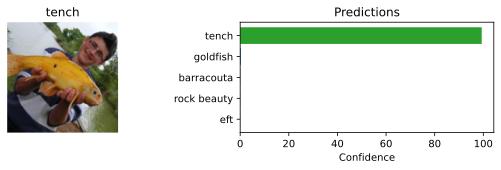

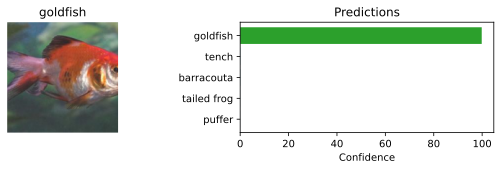

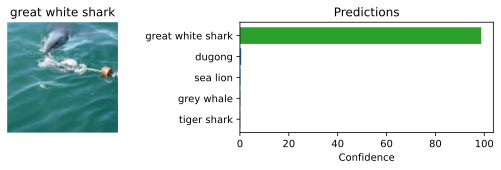

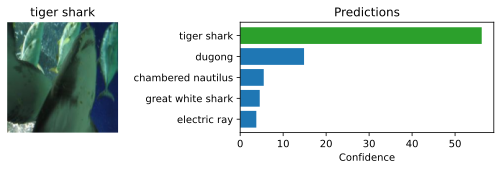

In [11]:
# keep a batch of original images for comparisons later
exmp_batch, label_batch = next(iter(data_loader))

# predict the categories without calculating gradients
with torch.no_grad():
    preds = pretrained_model(exmp_batch.to(device))

# display four images and their five highest scoring categories
for i in [1, 6, 11, 16]:
    show_prediction(exmp_batch[i], label_batch[i], preds[i])

The bar plot on the right shows the top-5 predictions of the model with their class probabilities. We denote the class probabilities with "confidence" as it somewhat resembles how confident the network is that the image is of one specific class. Some of the images have a highly peaked probability distribution, and we would expect the model to be rather robust against noise for those. However, we will see below that this is not always the case. Note that all of the images are of fish because the data loader doesn't shuffle the dataset. Otherwise, we would get different images every time we run the notebook, which would make it hard to discuss the results on the static version.

### Adversarial Patches

Instead of changing every pixel by a little bit, we can also try to change a small part of the image into whatever values we would like. In other words, we will create a small image patch that covers a minor part of the original image but causes the model to confidentially predict a specific class we choose. This form of attack is an even bigger threat in real-world applications than FSGM. Imagine a network in an autonomous car that receives a live image from a camera. Another driver could print out a specific pattern and put it on the back of his/her vehicle to make the autonomous car believe that the car is actually a pedestrian. Meanwhile, humans would not notice it. [Tom Brown et al.](https://arxiv.org/pdf/1712.09665.pdf) proposed a way of learning such adversarial image patches robustly in 2017 and provided a short demonstration on [YouTube](https://youtu.be/i1sp4X57TL4). Interestingly, if you add a small picture of the target class (here *toaster*) to the original image, the model does not pick it up at all. A specifically designed patch, however, which only roughly looks like a toaster, can change the network's prediction instantaneously.

[![Adversarial patch in real world](https://img.youtube.com/vi/i1sp4X57TL4/0.jpg)](https://youtu.be/i1sp4X57TL4)

Let's take a closer look at how we can actually train such patches. We calculate gradients for the input, and update our adversarial input correspondingly. We do not calculate a gradient for every pixel. Instead, we replace parts of the input image with our patch and then calculate the gradients just for our patch. Secondly, we don't just do it for one image, but we want the patch to work with any possible image. Hence, we have a whole training loop where we train the patch using SGD. Lastly, image patches are usually designed to make the model predict a specific class, not just any other arbitrary class except the true label. For instance, we can try to create a patch for the class "toaster" and train the patch so that our pretrained model predicts the class "toaster" for any image with the patch in it.

[Brown et al.](https://arxiv.org/pdf/1712.09665.pdf) randomly rotated and scaled the patch during training before placing it at a random position in an input image. This makes the patch more robust to small changes and is necessary if we want to fool a neural network in a real-world application.

This tutorial only shows how to make the patch robust to the location in the image.

Here is where you could:
* Randomly rotate patch
* Randomly scale the patch
* Improve random location of patch in the image

In [29]:
# optionally rotate and flip the patch before placing it
def place_patch(img, patch, augment=False):
    patched_images = img.clone()

    for i in range(img.shape[0]):
        transformed_patch = patch

        if augment:
            # randomly choose zero, one, two, or three quarter turns
            turns = np.random.randint(0, 4)
            transformed_patch = torch.rot90(
                transformed_patch,
                turns,
                dims=[1, 2]
            )

            # flip horizontally with a probability of one half
            if np.random.random() < 0.5:
                transformed_patch = torch.flip(
                    transformed_patch,
                    dims=[2]
                )

        # get the patch dimensions after transformation
        patch_height = transformed_patch.shape[1]
        patch_width = transformed_patch.shape[2]

        # choose a position where the entire patch fits
        top = np.random.randint(0, img.shape[2] - patch_height + 1)
        left = np.random.randint(0, img.shape[3] - patch_width + 1)

        # insert the transformed patch into the copied image
        patched_images[
            i,
            :,
            top:top + patch_height,
            left:left + patch_width
        ] = patch_forward(transformed_patch)

    return patched_images

print("optional patch transformations ready")

optional patch transformations ready


The patch itself will be an `nn.Parameter` whose values are in the range between $-\infty$ and $\infty$. Images are, however, naturally limited in their range, and thus we write a small function that maps the parameter into the image value range of ImageNet:

In [13]:
# arrange the normalization values for three color channels
TENSOR_MEANS = torch.tensor(NORM_MEAN, dtype=torch.float32)[:, None, None]
TENSOR_STD = torch.tensor(NORM_STD, dtype=torch.float32)[:, None, None]

# convert the trainable patch into normalized image values
def patch_forward(patch):
    # map unrestricted values into the pixel range from zero to one
    pixel_values = (torch.tanh(patch) + 1) / 2

    # apply the same normalization used for our images
    normalized_patch = (pixel_values - TENSOR_MEANS) / TENSOR_STD

    return normalized_patch

print("patch functions ready")

patch functions ready


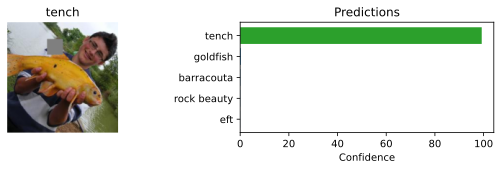

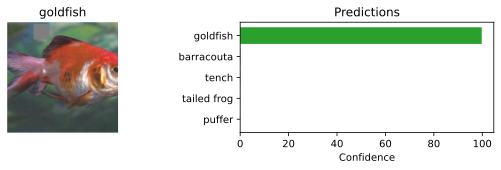

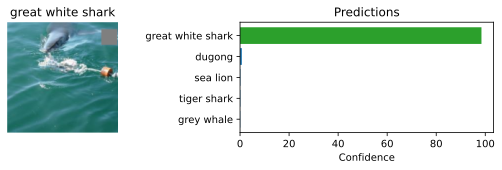

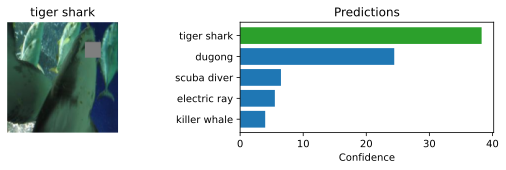

original images unchanged: True


In [15]:
# save a copy before placing any patches
original_check = exmp_batch.clone()

# create an untrained patch with three color channels
test_patch = torch.zeros(3, 32, 32)

# place the patch on copies of our example images
test_images = place_patch(exmp_batch, test_patch)

# check how the model predicts these patched images
with torch.no_grad():
    test_predictions = pretrained_model(test_images.to(device))

# display the same four examples with their patches
for i in [1, 6, 11, 16]:
    show_prediction(test_images[i], label_batch[i], test_predictions[i])

# compare the original batch with the copy saved before placement
print("original images unchanged:", torch.equal(exmp_batch, original_check))

Before looking at the actual training code, we can write a small evaluation function. We evaluate the success of a patch by how many times we were able to fool the network into predicting our target class. A simple function for this is implemented below.

In [16]:
# measure how often a patch causes the target prediction
def eval_patch(model, patch, val_loader, target_class):
    model.eval()

    target_top1 = 0
    target_top5 = 0
    total_trials = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="testing patch"):
            # exclude images that already belong to the target category
            eligible = labels != target_class

            # test four random patch positions per image
            for _ in range(4):
                patched_images = place_patch(images, patch)
                scores = model(patched_images.to(device))

                # move the eligibility mask to the same device as the scores
                eligible_gpu = eligible.to(device)

                # check whether the target is the highest prediction
                predictions = scores.argmax(dim=1)
                top1_hits = predictions == target_class
                target_top1 += (top1_hits & eligible_gpu).sum().item()

                # check whether the target appears among the top five
                top5_predictions = scores.topk(5, dim=1).indices
                top5_hits = (top5_predictions == target_class).any(dim=1)
                target_top5 += (top5_hits & eligible_gpu).sum().item()

                total_trials += eligible.sum().item()

    if total_trials == 0:
        raise ValueError("no images outside the target category were found")

    top1_rate = target_top1 / total_trials
    top5_rate = target_top5 / total_trials

    return top1_rate, top5_rate

print("patch evaluation function ready")

patch evaluation function ready


In [19]:
# search the available category names
search_word = "wolf"

matches = [
    name for name in label_names
    if search_word.lower() in name.lower()
]

print(matches)

['wolf spider', 'Irish wolfhound', 'timber wolf', 'white wolf', 'red wolf']


In [20]:
# choose the category we want the patch to encourage
target_name = "white wolf"
target_class = get_label_index(target_name)

# select a repeatable sample of 100 images
sample_generator = torch.Generator().manual_seed(42)
sample_indices = torch.randperm(
    len(dataset), generator=sample_generator
)[:100].tolist()

test_subset = data.Subset(dataset, sample_indices)

test_loader = data.DataLoader(
    test_subset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# measure the untrained gray patch on this sample
gray_top1, gray_top5 = eval_patch(
    pretrained_model,
    test_patch,
    test_loader,
    target_class
)

print("target category:", target_name)
print(f"gray patch top-1 target rate: {gray_top1:.2%}")
print(f"gray patch top-5 target rate: {gray_top5:.2%}")

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

target category: white wolf
gray patch top-1 target rate: 0.00%
gray patch top-5 target rate: 0.00%


In [21]:
# keep our test images out of the training set
test_indices = set(sample_indices)

remaining_indices = [
    i for i in range(len(dataset))
    if i not in test_indices
]

# shuffle the remaining indices in a repeatable way
train_generator = torch.Generator().manual_seed(42)
shuffled_positions = torch.randperm(
    len(remaining_indices),
    generator=train_generator
).tolist()

# choose 500 images for our first training experiment
train_indices = [
    remaining_indices[position]
    for position in shuffled_positions[:500]
]

train_subset = data.Subset(dataset, train_indices)

# shuffle the training images when starting each pass
train_loader = data.DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

# check the sizes and confirm that the sets are separate
overlap = set(train_indices).intersection(test_indices)

print("training images:", len(train_subset))
print("test images:", len(test_subset))
print("shared images:", len(overlap))
print("target category:", target_name)

training images: 500
test images: 100
shared images: 0
target category: white wolf


Finally, we can look at the training loop. Given a model to fool, a target class to design the patch for, and a size $k$ of the patch in the number of pixels, we first start by creating a parameter of size $3\times k\times k$. These are the only parameters we will train, and the network itself remains untouched. We use a simple SGD optimizer with momentum to minimize the classification loss of the model given the patch in the image. While we first start with a very high loss due to the good initial performance of the network, the loss quickly decreases once we start changing the patch. In the end, the patch will represent patterns that are characteristic of the class. For instance, if we would want the model to predict a "goldfish" in every image, we would expect the pattern to look somewhat like a goldfish. Over the iterations, the model finetunes the pattern and, hopefully, achieves a high fooling accuracy.

In [30]:
# learn a patch that encourages our chosen target category
def patch_attack(model, target_class, patch_size=32, num_epochs=3, augment=False):
    model.eval()

    # start with zeros, which display as a gray patch
    patch = nn.Parameter(
        torch.zeros(3, patch_size, patch_size)
    )

    # update only the patch values
    optimizer = torch.optim.SGD(
        [patch],
        lr=0.1,
        momentum=0.8
    )

    # measure how far predictions are from the target category
    loss_function = nn.CrossEntropyLoss()
    loss_history = []

    for epoch in range(num_epochs):
        total_loss = 0.0
        total_images = 0

        for images, _ in tqdm(
            train_loader,
            desc=f"epoch {epoch + 1}/{num_epochs}"
        ):
            # clear gradients left over from the previous batch
            optimizer.zero_grad()

            # place the patch and predict the image categories
            # optionally rotate and flip the patch during training
            patched_images = place_patch(images, patch, augment=augment)
            scores = model(patched_images.to(device))

            # ask every image to produce the target prediction
            target_labels = torch.full(
                (images.size(0),),
                target_class,
                dtype=torch.long,
                device=device
            )

            loss = loss_function(scores, target_labels)

            # calculate how patch values affect the loss
            loss.backward()

            # adjust the patch to reduce the loss
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_images += images.size(0)

        average_loss = total_loss / total_images
        loss_history.append(average_loss)

        print(
            f"epoch {epoch + 1}: "
            f"average loss = {average_loss:.4f}"
        )

    # return the learned values without their gradient history
    return patch.detach(), loss_history

print("patch training function ready")

patch training function ready




*   nn.Parameter marks the patch’s numbers as values we want to learn.
*  Loss measures how poorly the predictions match our requested target, “white wolf.” Lower loss means the training objective is improving.
-  loss.backward() calculates how changing the patch would affect that loss.
- optimizer.step() updates the patch. The model’s weights stay frozen.
- An epoch is one pass through the 500 training images.

In [23]:
# train a baseline patch using random placement
baseline_patch, baseline_loss_history = patch_attack(
    model=pretrained_model,
    target_class=target_class,
    patch_size=32,
    num_epochs=3
)

# confirm that training returned the expected patch size
print("training complete")
print("patch shape:", baseline_patch.shape)

epoch 1/3:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: average loss = 16.5978


epoch 2/3:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 2: average loss = 16.2752


epoch 3/3:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 3: average loss = 16.0305
training complete
patch shape: torch.Size([3, 32, 32])


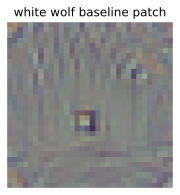

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

target category: white wolf
gray patch top-1 target rate: 0.00%
trained patch top-1 target rate: 0.00%
gray patch top-5 target rate: 0.00%
trained patch top-5 target rate: 0.25%


In [24]:
# convert the learned patch values into displayable pixel values
patch_pixels = (torch.tanh(baseline_patch) + 1) / 2

# rearrange the dimensions from channels first to channels last
patch_image = patch_pixels.cpu().permute(1, 2, 0).numpy()

# display the patch without smoothing its pixels
plt.figure(figsize=(3, 3))
plt.imshow(patch_image, interpolation="nearest")
plt.title("white wolf baseline patch")
plt.axis("off")
plt.show()

# test the learned patch on images excluded from training
baseline_top1_rate, baseline_top5_rate = eval_patch(
    pretrained_model,
    baseline_patch,
    test_loader,
    target_class
)

# compare target prediction rates before and after training
print("target category:", target_name)
print(f"gray patch top-1 target rate: {gray_top1:.2%}")
print(f"trained patch top-1 target rate: {baseline_top1_rate:.2%}")
print(f"gray patch top-5 target rate: {gray_top5:.2%}")
print(f"trained patch top-5 target rate: {baseline_top5_rate:.2%}")

In [25]:
# train a new patch for longer while keeping its size unchanged
longer_patch, longer_loss_history = patch_attack(
    model=pretrained_model,
    target_class=target_class,
    patch_size=32,
    num_epochs=30
)

# compare the beginning and end of this training run
print("training complete")
print(f"first epoch loss: {longer_loss_history[0]:.4f}")
print(f"final epoch loss: {longer_loss_history[-1]:.4f}")

epoch 1/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: average loss = 16.5234


epoch 2/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 2: average loss = 16.2217


epoch 3/30:   0%|          | 0/16 [00:00<?, ?it/s]

...

epoch 28: average loss = 10.5546


epoch 29/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 29: average loss = 10.5901


epoch 30/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 30: average loss = 10.5010
training complete
first epoch loss: 16.5234
final epoch loss: 10.5010


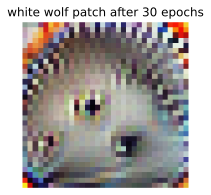

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

3 epochs top-1 target rate: 0.00%
30 epochs top-1 target rate: 0.00%
3 epochs top-5 target rate: 0.25%
30 epochs top-5 target rate: 0.25%


In [26]:
# display the patch after longer training
patch_pixels = (torch.tanh(longer_patch) + 1) / 2
patch_image = patch_pixels.cpu().permute(1, 2, 0).numpy()

plt.figure(figsize=(3, 3))
plt.imshow(patch_image, interpolation="nearest")
plt.title("white wolf patch after 30 epochs")
plt.axis("off")
plt.show()

# measure target predictions on our held-out sample
longer_top1_rate, longer_top5_rate = eval_patch(
    pretrained_model,
    longer_patch,
    test_loader,
    target_class
)

# compare the two training durations
print(f"3 epochs top-1 target rate: {baseline_top1_rate:.2%}")
print(f"30 epochs top-1 target rate: {longer_top1_rate:.2%}")
print(f"3 epochs top-5 target rate: {baseline_top5_rate:.2%}")
print(f"30 epochs top-5 target rate: {longer_top5_rate:.2%}")

In [27]:
# train a larger patch using the same target and training duration
large_patch, large_loss_history = patch_attack(
    model=pretrained_model,
    target_class=target_class,
    patch_size=64,
    num_epochs=30
)

# evaluate the larger patch on our validation sample
large_top1_rate, large_top5_rate = eval_patch(
    pretrained_model,
    large_patch,
    test_loader,
    target_class
)

# compare patches trained for the same number of epochs
print(f"32 pixel patch top-1 target rate: {longer_top1_rate:.2%}")
print(f"64 pixel patch top-1 target rate: {large_top1_rate:.2%}")
print(f"32 pixel patch top-5 target rate: {longer_top5_rate:.2%}")
print(f"64 pixel patch top-5 target rate: {large_top5_rate:.2%}")
print(f"final training loss: {large_loss_history[-1]:.4f}")

epoch 1/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: average loss = 15.3476


epoch 2/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 2: average loss = 13.2198


epoch 3/30:   0%|          | 0/16 [00:00<?, ?it/s]

...

epoch 29: average loss = 0.6319


epoch 30/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 30: average loss = 0.5728


testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

32 pixel patch top-1 target rate: 0.00%
64 pixel patch top-1 target rate: 84.50%
32 pixel patch top-5 target rate: 0.25%
64 pixel patch top-5 target rate: 97.75%
final training loss: 0.5728


In [28]:
# create rotated and flipped versions of the trained patch
patch_versions = [
    ("original", large_patch),
    ("90 degrees", torch.rot90(large_patch, 1, dims=[1, 2])),
    ("180 degrees", torch.rot90(large_patch, 2, dims=[1, 2])),
    ("270 degrees", torch.rot90(large_patch, 3, dims=[1, 2])),
    ("horizontal flip", torch.flip(large_patch, dims=[2]))
]

# save the results for comparison after our creative modification
orientation_results = {}

for name, patch_version in patch_versions:
    # use the same random placement sequence for every version
    np.random.seed(123)

    top1_rate, top5_rate = eval_patch(
        pretrained_model,
        patch_version,
        test_loader,
        target_class
    )

    orientation_results[name] = (top1_rate, top5_rate)

# display the results together
for name, rates in orientation_results.items():
    print(f"{name}: top-1 = {rates[0]:.2%}, top-5 = {rates[1]:.2%}")

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

original: top-1 = 85.00%, top-5 = 97.50%
90 degrees: top-1 = 0.00%, top-5 = 0.50%
180 degrees: top-1 = 0.00%, top-5 = 0.00%
270 degrees: top-1 = 0.00%, top-5 = 0.00%
horizontal flip: top-1 = 58.00%, top-5 = 86.00%


In [31]:
# train a new patch with random rotations and horizontal flips
robust_patch, robust_loss_history = patch_attack(
    model=pretrained_model,
    target_class=target_class,
    patch_size=64,
    num_epochs=30,
    augment=True
)

# report how the training objective changed
print("augmented training complete")
print(f"first epoch loss: {robust_loss_history[0]:.4f}")
print(f"final epoch loss: {robust_loss_history[-1]:.4f}")

epoch 1/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: average loss = 15.3916


epoch 2/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 2: average loss = 13.7069


epoch 3/30:   0%|          | 0/16 [00:00<?, ?it/s]

...

epoch 28: average loss = 9.7699


epoch 29/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 29: average loss = 9.6869


epoch 30/30:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 30: average loss = 9.6330
augmented training complete
first epoch loss: 15.3916
final epoch loss: 9.6330


In [32]:
# prepare the same five orientations for the new patch
robust_versions = [
    ("original", robust_patch),
    ("90 degrees", torch.rot90(robust_patch, 1, dims=[1, 2])),
    ("180 degrees", torch.rot90(robust_patch, 2, dims=[1, 2])),
    ("270 degrees", torch.rot90(robust_patch, 3, dims=[1, 2])),
    ("horizontal flip", torch.flip(robust_patch, dims=[2]))
]

robust_orientation_results = {}

for name, patch_version in robust_versions:
    # match the placement sequence used for the baseline patch
    np.random.seed(123)

    top1_rate, top5_rate = eval_patch(
        pretrained_model,
        patch_version,
        test_loader,
        target_class
    )

    robust_orientation_results[name] = (top1_rate, top5_rate)

# compare top-1 target rates for both training methods
print("top-1 target rates: baseline versus augmented")

for name in robust_orientation_results:
    baseline_rate = orientation_results[name][0]
    augmented_rate = robust_orientation_results[name][0]

    print(
        f"{name}: baseline = {baseline_rate:.2%}, "
        f"augmented = {augmented_rate:.2%}"
    )

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

top-1 target rates: baseline versus augmented
original: baseline = 85.00%, augmented = 0.00%
90 degrees: baseline = 0.00%, augmented = 0.00%
180 degrees: baseline = 0.00%, augmented = 0.00%
270 degrees: baseline = 0.00%, augmented = 0.00%
horizontal flip: baseline = 58.00%, augmented = 0.00%


In [33]:
# exclude every image used for training or validation
used_indices = set(train_indices) | set(sample_indices)

available_indices = [
    i for i in range(len(dataset))
    if i not in used_indices
]

# randomly select a fresh sample in a repeatable way
final_generator = torch.Generator().manual_seed(2026)
positions = torch.randperm(
    len(available_indices),
    generator=final_generator
)[:100].tolist()

final_indices = [available_indices[i] for i in positions]

final_loader = data.DataLoader(
    data.Subset(dataset, final_indices),
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# test both patches in the same five orientations
final_results = {}

for method, versions in [
    ("baseline", patch_versions),
    ("augmented", robust_versions)
]:
    for orientation, patch_version in versions:
        # match placement positions across all comparisons
        np.random.seed(123)

        rates = eval_patch(
            pretrained_model,
            patch_version,
            final_loader,
            target_class
        )

        final_results[(method, orientation)] = rates

# display the final results
print("fresh test images:", len(final_indices))

for (method, orientation), (top1, top5) in final_results.items():
    print(
        f"{method}, {orientation}: "
        f"top-1 = {top1:.2%}, top-5 = {top5:.2%}"
    )

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

...

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

testing patch:   0%|          | 0/4 [00:00<?, ?it/s]

fresh test images: 100
baseline, original: top-1 = 85.61%, top-5 = 99.24%
baseline, 90 degrees: top-1 = 0.00%, top-5 = 0.00%
baseline, 180 degrees: top-1 = 0.00%, top-5 = 0.00%
baseline, 270 degrees: top-1 = 0.00%, top-5 = 0.25%
baseline, horizontal flip: top-1 = 57.07%, top-5 = 88.89%
augmented, original: top-1 = 0.00%, top-5 = 0.00%
augmented, 90 degrees: top-1 = 0.00%, top-5 = 0.00%
augmented, 180 degrees: top-1 = 0.00%, top-5 = 0.00%
augmented, 270 degrees: top-1 = 0.00%, top-5 = 0.00%
augmented, horizontal flip: top-1 = 0.00%, top-5 = 0.00%


In [34]:
from PIL import Image
from google.colab import files

# convert the successful baseline patch into ordinary pixel colors
pixels = (torch.tanh(large_patch.detach()) + 1) / 2
pixels = pixels.clamp(0, 1)
pixels = pixels.cpu().permute(1, 2, 0).numpy()

# convert colors into whole numbers between zero and 255
pixel_array = np.round(pixels * 255).astype(np.uint8)
patch_image = Image.fromarray(pixel_array)

# save the original 64 by 64 pixel patch
patch_image.save("/content/white_wolf_patch_original.png")

# enlarge for printing while preserving the square pixel pattern
print_image = patch_image.resize(
    (1200, 1200),
    resample=Image.Resampling.NEAREST
)

# save a print version sized at four inches at 300 pixels per inch
print_path = "/content/white_wolf_patch_print.png"
print_image.save(print_path, dpi=(300, 300))

# download the print version to your computer
files.download(print_path)

print("print file ready")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

print file ready


To get some experience with what to expect from an adversarial patch attack, we want to train multiple patches for different classes. As the training of a patch can take one or two minutes on a GPU, we have provided a couple of pre-trained patches including their results on the full dataset. The results are saved in a JSON file, which is loaded below.

In [ ]:
# Load evaluation results of the pretrained patches
json_results_file = os.path.join(CHECKPOINT_PATH, "patch_results.json")
json_results = {}
if os.path.isfile(json_results_file):
    with open(json_results_file, "r") as f:
        json_results = json.load(f)

# If you train new patches, you can save the results via calling this function
def save_results(patch_dict):
    result_dict = {cname: {psize: [t.item() if isinstance(t, torch.Tensor) else t
                                   for t in patch_dict[cname][psize]["results"]]
                           for psize in patch_dict[cname]}
                   for cname in patch_dict}
    with open(os.path.join(CHECKPOINT_PATH, "patch_results.json"), "w") as f:
        json.dump(result_dict, f, indent=4)

Additionally, we implement a function to train and evaluate patches for a list of classes and patch sizes. The pretrained patches include the classes *toaster*, *goldfish*, *school bus*, *lipstick*, and *pineapple*. We chose the classes arbitrarily to cover multiple domains (animals, vehicles, fruits, devices, etc.). We trained each class for three different patch sizes: $32\times32$ pixels, $48\times48$ pixels, and $64\times64$ pixels. We can load them in the two cells below.

In [ ]:
def get_patches(class_names, patch_sizes):
    result_dict = dict()

    # Loop over all classes and patch sizes
    for name in class_names:
        result_dict[name] = dict()
        for patch_size in patch_sizes:
            c = label_names.index(name)
            file_name = os.path.join(CHECKPOINT_PATH, f"{name}_{patch_size}_patch.pt")
            # Load patch if pretrained file exists, otherwise start training
            if not os.path.isfile(file_name):
                patch, val_results = patch_attack(pretrained_model, target_class=c, patch_size=patch_size, num_epochs=5)
                print(f"Validation results for {name} and {patch_size}:", val_results)
                torch.save(patch, file_name)
            else:
                patch = torch.load(file_name)
            # Load evaluation results if exist, otherwise manually evaluate the patch
            if name in json_results:
                results = json_results[name][str(patch_size)]
            else:
                results = eval_patch(pretrained_model, patch, data_loader, target_class=c)

            # Store results and the patches in a dict for better access
            result_dict[name][patch_size] = {
                "results": results,
                "patch": patch
            }

    return result_dict

Feel free to add any additional classes and/or patch sizes.

In [ ]:
class_names = ['toaster', 'goldfish', 'school bus', 'lipstick', 'pineapple']
patch_sizes = [32, 48, 64]

patch_dict = get_patches(class_names, patch_sizes)
# save_results(patch_dict) # Uncomment if you add new class names and want to save the new results

Before looking at the quantitative results, we can actually visualize the patches.

In [ ]:
def show_patches():
    fig, ax = plt.subplots(len(patch_sizes), len(class_names), figsize=(len(class_names)*2.2, len(patch_sizes)*2.2))
    for c_idx, cname in enumerate(class_names):
        for p_idx, psize in enumerate(patch_sizes):
            patch = patch_dict[cname][psize]["patch"]
            patch = (torch.tanh(patch) + 1) / 2 # Parameter to pixel values
            patch = patch.cpu().permute(1, 2, 0).numpy()
            patch = np.clip(patch, a_min=0.0, a_max=1.0)
            ax[p_idx][c_idx].imshow(patch)
            ax[p_idx][c_idx].set_title(f"{cname}, size {psize}")
            ax[p_idx][c_idx].axis('off')
    fig.subplots_adjust(hspace=0.3, wspace=0.3)
    plt.show()
show_patches()

We can see a clear difference between patches of different classes and sizes. In the smallest size, $32\times 32$ pixels, some of the patches clearly resemble their class. For instance, the goldfish patch clearly shows a goldfish. The eye and the color are very characteristic of the class. Overall, the patches with $32$ pixels have very strong colors that are typical for their class (yellow school bus, pink lipstick, greenish pineapple). The larger the patch becomes, the more stretched the pattern becomes. For the goldfish, we can still spot regions that might represent eyes and the characteristic orange color, but it is not clearly a single fish anymore. For the pineapple, we might interpret the top part of the image as the leaves of pineapple fruit, but it is more abstract than our small patches. Nevertheless, we can easily spot the alignment of the patch to class, even on the largest scale.

Let's now look at the quantitative results.

In [ ]:
%%html
<!-- Some HTML code to increase font size in the following table -->
<style>
th {font-size: 120%;}
td {font-size: 120%;}
</style>

In [ ]:
import tabulate
from IPython.display import display, HTML

def show_table(top_1=True):
    i = 0 if top_1 else 1
    table = [[name] + [f"{(100.0 * patch_dict[name][psize]['results'][i]):4.2f}%" for psize in patch_sizes]
             for name in class_names]
    display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["Class name"] + [f"Patch size {psize}x{psize}" for psize in patch_sizes])))

First, we will create a table of top-1 accuracy, meaning that how many images have been classified with the target class as highest prediction?

In [ ]:
show_table(top_1=True)

The clear trend, that we would also have expected, is that the larger the patch, the easier it is to fool the model. For the largest patch size of $64\times 64$, we are able to fool the model on almost all images, despite the patch covering only 8% of the image. The smallest patch actually covers 2% of the image, which is almost neglectable. Still, the fooling accuracy is quite remarkable. A large variation can be however seen across classes. While *school bus* and *pineapple* seem to be classes that were easily predicted, *toaster* and *lipstick* seem to be much harder for creating a patch. It is hard to intuitively explain why our patches underperform on those classes. Nonetheless, a fooling accuracy of >40% is still very good for such a tiny patch.

Let's also take a look at the top-5 accuracy:

In [ ]:
show_table(top_1=False)

We see a very similar pattern across classes and patch sizes. The patch size $64$ obtains >99.7% top-5 accuracy for any class, showing that we can almost fool the network on any image. A top-5 accuracy of >70% for the hard classes and small patches is still impressive and shows how vulnerable deep CNNs are to such attacks.

Finally, let's create some example visualizations of the patch attack in action.

In [ ]:
def perform_patch_attack(patch):
    patch_batch = exmp_batch.clone()
    patch_batch = place_patch(patch_batch, patch)
    with torch.no_grad():
        patch_preds = pretrained_model(patch_batch.to(device))
    for i in range(1,17,5):
        show_prediction(patch_batch[i], label_batch[i], patch_preds[i])

In [ ]:
perform_patch_attack(patch_dict['goldfish'][32]['patch'])

The tiny goldfish patch can change all of the predictions to "goldfish" as top class. Note that the patch attacks work especially well if the input image is semantically similar to the target class (e.g. a fish and the target class "goldfish" works better than an airplane image with that patch). Nevertheless, we can also let the network predict semantically dis-similar classes by using a larger patch:

In [ ]:
perform_patch_attack(patch_dict['school bus'][64]['patch'])

Although none of the images have anything to do with an American school bus, the high confidence of often 100% shows how powerful such attacks can be. With a few lines of code and access to the model, we were able to generate patches that we add to any image to make the model predict any class we want.

## References

This tutorial was originally created by Phillip Lippe.
[![View notebooks on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial10/Adversarial_Attacks.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial10/Adversarial_Attacks.ipynb)  

[1] Goodfellow, Ian J., Jonathon Shlens, and Christian Szegedy. "Explaining and harnessing adversarial examples." ICLR 2015.

[2] Hendrik Metzen, Jan, et al. "Universal adversarial perturbations against semantic image segmentation." Proceedings of the IEEE International Conference on Computer Vision. 2017.

[3] Anant Jain. "Breaking neural networks with adversarial attacks." [Blog post](https://towardsdatascience.com/breaking-neural-networks-with-adversarial-attacks-f4290a9a45aa) 2019.